# 05 · Design optimisation for future demands

Calibration asked: *which parameters make the model match what exists?*
Design optimisation asks: *which hardware should we build so that the model
predicts what we want?* The mathematics is the same family – minimise something
over parameters – but three things change:

* **You choose the objective**, and there is usually more than one (NVH, mass,
  durability, cost). Conflicting objectives have no single optimum, only a set
  of best compromises.
* **Constraints** carry the engineering: packaging limits, allowable torque,
  travel. Optima almost always sit *on* constraints.
* The model is used **outside the conditions it was calibrated in**. Parameter
  uncertainty and production tolerances now matter, because the optimiser will
  happily exploit every weakness of the model.

We use the fast linear model with the parameters calibrated in notebook 03.
(If your design model is expensive, do exactly the same on a surrogate, as in
notebook 04.)

## 1 · The scenario

The next engine generation delivers **20 % more gas torque** and revs to
**11500 rpm**. The clutch torsional damper and the flywheel mass can be changed.

| | Symbol | Range | Meaning |
|---|---|---|---|
| Design variable | `k_damper` | 700 … 3200 Nm/rad | clutch-damper stiffness |
| Design variable | `c_damper` | 0.20 … 0.60 Nms/rad | clutch-damper damping (limited by the friction package) |
| Design variable | `J_add` | 0 … 0.012 kgm² | extra flywheel inertia on the crank |
| Objective 1 | rattle index | minimise | rms angular acceleration of the gearbox input shaft over the run-up, all orders |
| Objective 2 | `J_add` | minimise | mass, cost and throttle response all suffer from flywheel inertia |
| Constraint | wind-up | ≤ 0.30 rad | peak damper angle (mean + vibratory torque, full load) must stay within the damper travel |

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, differential_evolution, NonlinearConstraint
from scipy.stats import qmc

import driveline as dl
import plotstyle
C = plotstyle.use()
np.set_printoptions(precision=4, suppress=True)

cal = np.load("data/calibration.npz")
x_cal, cov_cal = cal["x_A"], cal["cov_A"]          # calibrated parameters and their covariance (ln units)
i_k, i_c, i_gas = (dl.NAMES.index(n) for n in ("k_damper", "c_damper", "gas_scale"))

RPM_F = np.arange(2000.0, 11501.0, 100.0)          # future run-up
ORD_F = np.arange(0.5, 6.01, 0.5)                  # all orders up to 6
VARS = ["k_damper", "c_damper", "J_add"]
LO = np.array([700.0, 0.20, 0.0])
HI = np.array([3200.0, 0.60, 0.012])
WINDUP_MAX = 0.30
GAS_FUTURE = 1.20


def evaluate(d, gas=GAS_FUTURE, x=None):
    """Design d = (k_damper, c_damper, J_add)  ->  (rattle index [rad/s²], wind-up [rad])."""
    x = np.array(x_cal if x is None else x, float)
    x[i_k], x[i_c] = d[0], d[1]
    x[i_gas] *= gas
    fixed = dict(dl.FIXED, J_crank=dl.FIXED["J_crank"] + d[2])
    _, ex = dl.simulate(x, rpm=RPM_F, orders=ORD_F, full_output=True, fixed=fixed)
    acc = np.sqrt((ex["acc_gbx"] ** 2).sum(axis=0) / 2)         # rms over all orders, per rpm
    t_peak = (ex["t_mean"] + ex["t_damper"].sum(axis=0)).max()    # conservative: order peaks add up
    return np.array([np.sqrt(np.mean(acc ** 2)), t_peak / x[i_k]])


d_today = np.array([x_cal[i_k], x_cal[i_c], 0.0])
today = evaluate(d_today, gas=1.0)
future_same = evaluate(d_today)
print(f"{'':28s} {'rattle [rad/s²]':>16s} {'wind-up [rad]':>14s}")
print(f"{'today':28s} {today[0]:16.0f} {today[1]:14.3f}")
print(f"{'future engine, same hardware':28s} {future_same[0]:16.0f} {future_same[1]:14.3f}   ← violates {WINDUP_MAX}")

                              rattle [rad/s²]  wind-up [rad]
today                                    7868          0.294
future engine, same hardware             9402          0.353   ← violates 0.3


With unchanged hardware the new engine is about 20 % worse in rattle and
exceeds the damper travel. Something has to change.

Two remarks on the problem formulation, because that is where most of the
engineering sits:

* The **rattle index** squeezes a whole run-up, eleven orders, into one number.
  Any such aggregation hides things (a narrow, severe resonance and a broad mild
  one can score the same). Always look at the curves of the final candidates.
* The **wind-up** adds the order amplitudes arithmetically. That is a
  conservative bound; a time-domain model would give the true peak. Constraints
  deserve the same care in definition as objectives.

## 2 · A first look: sample the design space

Before optimising, sample. With three variables and a 1 ms model, 4096 Sobol
points cost a few seconds and show the whole landscape.

4096 designs in 3.7 s;  feasible: 81 %


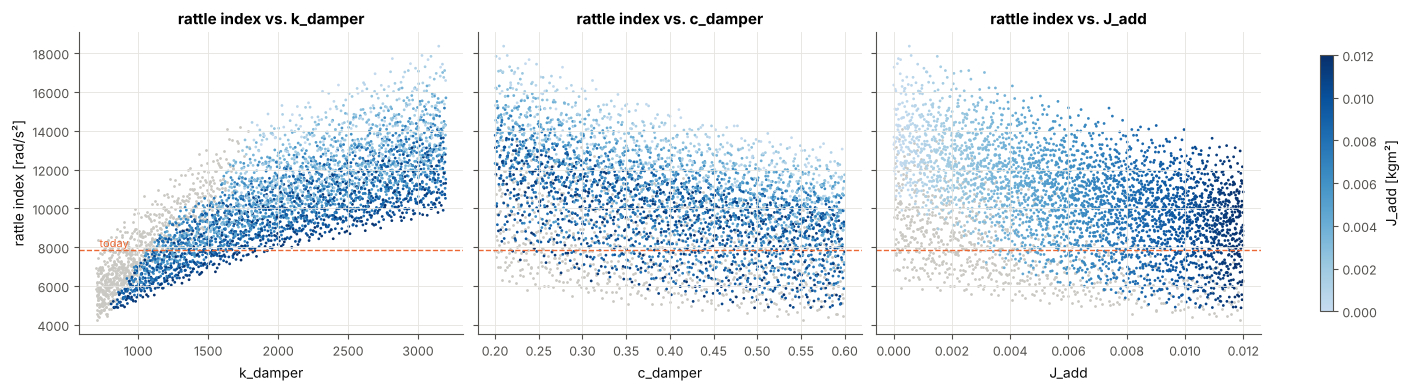

In [2]:
U = qmc.Sobol(d=3, seed=0).random(4096)
X = LO + U * (HI - LO)
t0 = time.perf_counter()
Y = np.array([evaluate(d) for d in X])
print(f"{len(X)} designs in {time.perf_counter() - t0:.1f} s;  feasible: {100 * np.mean(Y[:, 1] <= WINDUP_MAX):.0f} %")
feas = Y[:, 1] <= WINDUP_MAX

from matplotlib.colors import ListedColormap
blues = ListedColormap(plt.cm.Blues(np.linspace(0.25, 1.0, 256)))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, j in zip(axes, range(3)):
    a.scatter(X[~feas, j], Y[~feas, 0], s=4, color="#c9c8c2", linewidths=0, label="violates wind-up")
    sc = a.scatter(X[feas, j], Y[feas, 0], s=4, c=X[feas, 2], cmap=blues, vmin=0, vmax=0.012, linewidths=0)
    a.axhline(today[0], color=C[1], lw=1, ls="--")
    a.set(xlabel=VARS[j], title=f"rattle index vs. {VARS[j]}")
axes[0].set_ylabel("rattle index [rad/s²]")
axes[0].text(LO[0], today[0], " today", color=C[1], va="bottom", fontsize=8)
fig.colorbar(sc, ax=axes, label="J_add [kgm²]", shrink=0.85)
plt.show()

Grey designs violate the wind-up limit; darker blue means more added inertia.
Soft dampers are better for rattle but infeasible unless inertia is added; more
damping always helps in this model, so `c_damper` will end up on its upper bound.

## 3 · Single objective with constraints

First the classic form: **minimise rattle subject to wind-up ≤ 0.30 rad and an
inertia budget J_add ≤ 0.004 kgm².**

$$\min_{\mathbf{d}} f(\mathbf{d})\quad\text{s.t.}\quad g(\mathbf{d}) \le 0,\quad \mathbf{d}_{lo}\le\mathbf{d}\le\mathbf{d}_{hi}$$

Two solver families:

* **Gradient-based (SLSQP, trust-constr, IPOPT)** – fast, handle constraints
  natively, find a *local* optimum; need smooth functions. Use multi-start.
* **Population-based (differential evolution, CMA-ES, NSGA-II)** – global, need
  no gradients, tolerate noise and kinks, cost 10–100× more runs.

As always we optimise in scaled variables $u\in[0,1]^3$.

In [3]:
def to_d(u):
    return LO + np.asarray(u) * (HI - LO)


class Problem:
    """Counts evaluations and caches the last one (objective and constraint share a run)."""
    def __init__(self, fun=None):
        self.n, self._u, self._y = 0, None, None
        self.fun = fun or (lambda u: evaluate(to_d(u)))

    def __call__(self, u):
        u = np.asarray(u, float)
        if self._u is None or not np.array_equal(u, self._u):
            self._u, self._y = u.copy(), self.fun(u)
            self.n += 1
        return self._y


def solve_slsqp(j_budget, starts, prob=None, windup_max=WINDUP_MAX):
    prob = prob or Problem()
    u_budget = j_budget / HI[2]
    best = None
    for u0 in starts:
        r = minimize(lambda u: prob(u)[0] / 1e4, np.minimum(u0, [1, 1, u_budget]), method="SLSQP",
                     bounds=[(0, 1), (0, 1), (0, u_budget)],
                     constraints=[dict(type="ineq", fun=lambda u: (windup_max - prob(u)[1]) / windup_max)],
                     options=dict(ftol=1e-9, maxiter=200))
        ok = r.success and prob(r.x)[1] <= windup_max * 1.001
        if ok and (best is None or r.fun < best.fun):
            best = r
    return best, prob


starts = qmc.Sobol(d=3, seed=2).random(8)
t0 = time.perf_counter()
r_sq, p_sq = solve_slsqp(0.004, starts)
t_sq = time.perf_counter() - t0

p_de = Problem()
t0 = time.perf_counter()
r_de = differential_evolution(lambda u: p_de(u)[0] / 1e4, [(0, 1), (0, 1), (0, 0.004 / HI[2])],
                              constraints=NonlinearConstraint(lambda u: p_de(u)[1], -np.inf, WINDUP_MAX),
                              seed=0, tol=1e-8, polish=False)
t_de = time.perf_counter() - t0

print(f"{'':24s} {'k_damper':>9s} {'c_damper':>9s} {'J_add':>8s} {'rattle':>8s} {'wind-up':>8s} {'runs':>6s}")
for lab, r, p in (("SLSQP, 8 starts", r_sq, p_sq), ("differential evolution", r_de, p_de)):
    d = to_d(r.x); y = evaluate(d)
    print(f"{lab:24s} {d[0]:9.0f} {d[1]:9.3f} {d[2]:8.4f} {y[0]:8.0f} {y[1]:8.3f} {p.n:6d}")
d_opt = to_d(r_sq.x)

                          k_damper  c_damper    J_add   rattle  wind-up   runs
SLSQP, 8 starts               1081     0.600   0.0040     6683    0.300    453
differential evolution        1081     0.600   0.0040     6683    0.300   6599


Both methods agree. Look at *where* the optimum is: `c_damper` on its upper
bound, `J_add` on the budget, wind-up exactly on its limit. **All three
restrictions are active; the design is entirely determined by constraints.**
That is the normal situation in engineering optimisation, with two consequences:

* The result is only as good as the constraint values. Relaxing an active
  constraint is where the real gains are – worth a conversation with whoever
  owns the 0.30 rad or the 0.004 kgm².
* A design sitting exactly on a limit has no margin. Section 5 deals with that.

## 4 · Two objectives: the Pareto front

How much rattle does each bit of flywheel buy? Instead of fixing the inertia
budget we treat `J_add` as a second objective. A design is **Pareto-optimal**
if no other feasible design is better in one objective without being worse in
the other. The set of all such designs is the Pareto front – the menu of
sensible compromises. Choosing from the menu is a management decision; producing
the menu is the engineer's job.

Two standard ways to compute it:

* **ε-constraint**: turn one objective into a constraint (J_add ≤ ε), solve the
  single-objective problem, sweep ε. This is what we just did, repeated.
* **Non-dominated filtering** of a large sample, or evolutionary multi-objective
  algorithms (NSGA-II, e.g. in [pymoo](https://pymoo.org)), which evolve a whole
  front at once. Needed when there are three or more objectives or the front is
  disconnected.

ε-constraint front: 13 optimisations, 5967 runs


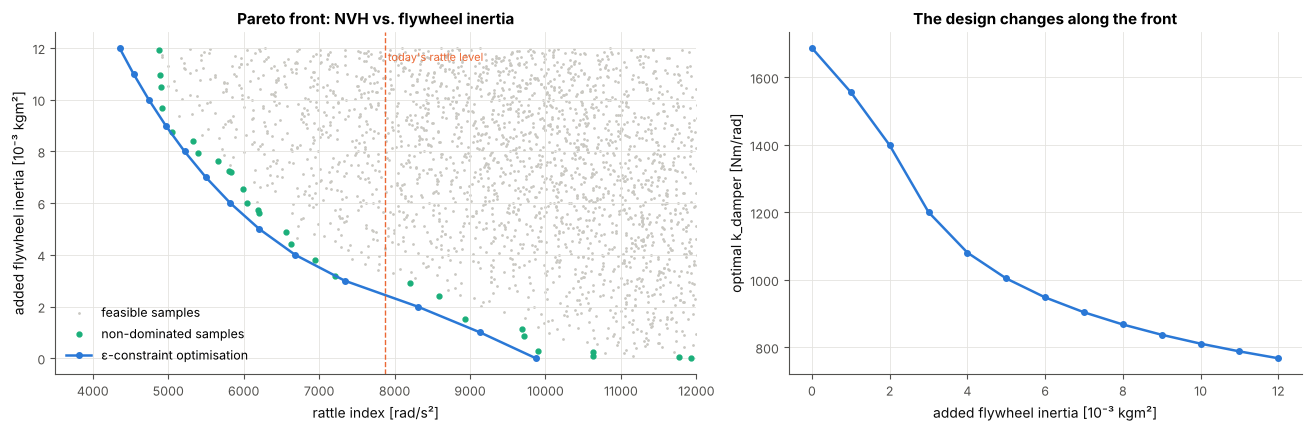

added inertia needed to keep today's rattle level with the new engine: 2.5·10⁻³ kgm² (12 % of the crank inertia)


In [4]:
def nondominated(F):
    """Indices of the non-dominated rows of F (all objectives minimised)."""
    order = np.argsort(F[:, 0])
    keep, best = [], np.inf
    for i in order:
        if F[i, 1] < best:
            keep.append(i); best = F[i, 1]
    return np.array(keep)


# (a) filter the Sobol sample from section 2
Ff = np.column_stack([Y[feas, 0], X[feas, 2]])
nd = nondominated(Ff)

# (b) epsilon-constraint sweep
budgets = np.linspace(0, 0.012, 13)
front, n_runs = [], 0
for b in budgets:
    r, p = solve_slsqp(max(b, 1e-9), starts)
    n_runs += p.n
    front.append(np.concatenate([to_d(r.x), evaluate(to_d(r.x))]))
front = np.array(front)
print(f"ε-constraint front: {len(budgets)} optimisations, {n_runs} runs")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), width_ratios=[1.25, 1])
ax[0].scatter(Y[feas, 0], X[feas, 2] * 1e3, s=4, color="#c9c8c2", linewidths=0, label="feasible samples")
ax[0].plot(Ff[nd, 0], Ff[nd, 1] * 1e3, "o", ms=3.5, color=C[2], label="non-dominated samples")
ax[0].plot(front[:, 3], front[:, 2] * 1e3, "o-", color=C[0], label="ε-constraint optimisation")
ax[0].axvline(today[0], color=C[1], lw=1, ls="--")
ax[0].text(today[0], 11.5, " today's rattle level", color=C[1], fontsize=8)
ax[0].set(xlabel="rattle index [rad/s²]", ylabel="added flywheel inertia [10⁻³ kgm²]",
          title="Pareto front: NVH vs. flywheel inertia", xlim=(3500, 12000))
ax[0].legend()
ax[1].plot(front[:, 2] * 1e3, front[:, 0], "o-", label="k_damper [Nm/rad]")
ax[1].set(xlabel="added flywheel inertia [10⁻³ kgm²]", ylabel="optimal k_damper [Nm/rad]",
          title="The design changes along the front")
plt.show()

j_need = np.interp(today[0], front[::-1, 3], front[::-1, 2])
print(f"added inertia needed to keep today's rattle level with the new engine: {j_need * 1e3:.1f}·10⁻³ kgm² "
      f"({100 * j_need / dl.FIXED['J_crank']:.0f} % of the crank inertia)")

How to read the front:

* Everything left of / below the blue line is unreachable; everything right of /
  above it is wasteful.
* The front shows **diminishing returns**: the first 4·10⁻³ kgm² of flywheel buy
  more rattle reduction than the following 8·10⁻³. Where the curve bends (a
  "knee") is the natural place to settle unless there is a hard target.
* The right-hand plot shows that the variables are **coupled**: more inertia
  reduces the vibratory torque, which frees wind-up travel, which lets the damper
  be softer. Optimising stiffness and inertia one after the other would miss this.
* The dashed line answers the business question directly: the inertia needed to
  hold today's NVH level with the stronger engine.

The cheap sample-and-filter front (green) is close to the optimised one and
cost no extra thought. For a first look it is often all you need.

## 5 · Robustness: optimum on paper vs. optimum in production

Take the design that just holds today's rattle level. It sits on the wind-up
limit. Now admit what we know about reality:

* the calibrated model parameters are uncertain (covariance from notebook 03),
* production parts scatter: say `k_damper` ±8 % and `c_damper` ±15 % (1σ, friction ages),
* the gas torque of the future engine is a forecast: ±3 %.

**Monte-Carlo propagation**: draw a few hundred random "worlds", evaluate the
design in each, look at the distribution of the results.

In [5]:
rng = np.random.default_rng(0)
N_MC = 256
ln_par = rng.multivariate_normal(np.zeros(dl.N_PAR), cov_cal, N_MC)       # calibration uncertainty
tol = np.column_stack([np.exp(0.08 * rng.standard_normal(N_MC)),           # k_damper scatter
                       np.exp(0.15 * rng.standard_normal(N_MC)),           # c_damper scatter
                       np.ones(N_MC)])
gas_mc = GAS_FUTURE * np.exp(0.03 * rng.standard_normal(N_MC))


def monte_carlo(d, n=N_MC):
    return np.array([evaluate(d * tol[i], gas=gas_mc[i], x=x_cal * np.exp(ln_par[i])) for i in range(n)])


r_nom, _ = solve_slsqp(j_need, starts)
d_nom = to_d(r_nom.x)
mc_nom = monte_carlo(d_nom)
print(f"nominal-optimal design: k = {d_nom[0]:.0f}, c = {d_nom[1]:.2f}, J_add = {d_nom[2] * 1e3:.1f}e-3")
print(f"  wind-up: nominal {evaluate(d_nom)[1]:.3f}, Monte-Carlo mean {mc_nom[:, 1].mean():.3f}, "
      f"95th percentile {np.percentile(mc_nom[:, 1], 95):.3f}")
print(f"  share of cases violating the limit: {100 * np.mean(mc_nom[:, 1] > WINDUP_MAX):.0f} %")

nominal-optimal design: k = 1304, c = 0.60, J_add = 2.5e-3
  wind-up: nominal 0.300, Monte-Carlo mean 0.301, 95th percentile 0.322
  share of cases violating the limit: 52 %


Roughly every second part would exceed the travel limit. Of course: the
optimiser placed the nominal design exactly on the limit, and scatter pushes
half of the population over it. **A deterministic optimum on an active
constraint is about 50 % unreliable by construction.**

**Robust design optimisation** puts the statistics into the problem statement:
require the 95th percentile of the wind-up (instead of its nominal value) to stay
below the limit, and minimise the mean rattle. Evaluating one design now costs
N Monte-Carlo runs. Two tricks keep this tractable:

* **Common random numbers** – use the *same* random worlds for every design.
  The objective then is a smooth deterministic function of the design and
  gradient-based optimisers keep working.
* A small sample (here 48) inside the optimisation, a large one to verify.

robust optimisation: 200 design evaluations × 48 worlds = 9600 runs, 9 s

                    k_damper  c_damper    J_add  rattle (mean)  wind-up p95  violations
nominal optimum         1304     0.600   0.0025           7915        0.322         52 %
robust optimum          1652     0.600   0.0025           9087        0.299          5 %


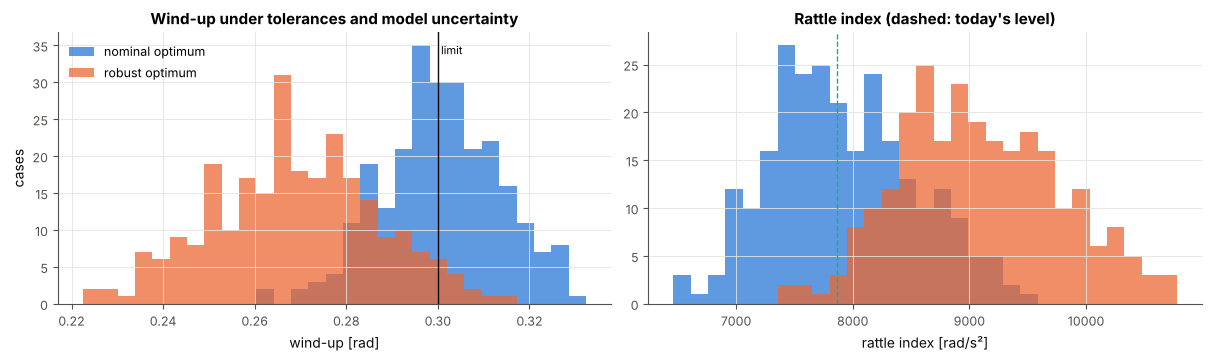

In [6]:
N_IN = 48


def robust_eval(u):
    mc = monte_carlo(to_d(u), N_IN)
    return np.array([mc[:, 0].mean(), np.percentile(mc[:, 1], 95)])


t0 = time.perf_counter()
r_rob, p_rob = solve_slsqp(j_need, starts[:3], prob=Problem(robust_eval))
d_rob = to_d(r_rob.x)
mc_rob = monte_carlo(d_rob)
print(f"robust optimisation: {p_rob.n} design evaluations × {N_IN} worlds = {p_rob.n * N_IN} runs, "
      f"{time.perf_counter() - t0:.0f} s")

print(f"\n{'':18s} {'k_damper':>9s} {'c_damper':>9s} {'J_add':>8s} {'rattle (mean)':>14s} {'wind-up p95':>12s} {'violations':>11s}")
for lab, d, mc in (("nominal optimum", d_nom, mc_nom), ("robust optimum", d_rob, mc_rob)):
    print(f"{lab:18s} {d[0]:9.0f} {d[1]:9.3f} {d[2]:8.4f} {mc[:, 0].mean():14.0f} "
          f"{np.percentile(mc[:, 1], 95):12.3f} {100 * np.mean(mc[:, 1] > WINDUP_MAX):10.0f} %")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
bins = np.linspace(min(mc_nom[:, 1].min(), mc_rob[:, 1].min()), mc_nom[:, 1].max(), 30)
ax[0].hist(mc_nom[:, 1], bins, alpha=0.75, label="nominal optimum")
ax[0].hist(mc_rob[:, 1], bins, alpha=0.75, label="robust optimum")
ax[0].axvline(WINDUP_MAX, color=plotstyle.INK, lw=1)
ax[0].text(WINDUP_MAX, ax[0].get_ylim()[1] * 0.92, " limit", fontsize=8)
ax[0].set(xlabel="wind-up [rad]", ylabel="cases", title="Wind-up under tolerances and model uncertainty")
ax[0].legend()
bins = np.linspace(min(mc_nom[:, 0].min(), mc_rob[:, 0].min()), max(mc_nom[:, 0].max(), mc_rob[:, 0].max()), 30)
ax[1].hist(mc_nom[:, 0], bins, alpha=0.75)
ax[1].hist(mc_rob[:, 0], bins, alpha=0.75)
ax[1].axvline(today[0], color=C[2], lw=1, ls="--")
ax[1].set(xlabel="rattle index [rad/s²]", title="Rattle index (dashed: today's level)")
plt.show()

The robust design uses a clearly stiffer damper with the same inertia budget. It
pays with roughly 15 % more rattle – the mean is now above today's level – and in
return keeps about 95 % of the cases inside the travel limit. This "price of robustness" is a number you can put on
the table; whether to pay it in rattle or in additional inertia is again a
decision along a Pareto front (exercise 3).

Which uncertainty is responsible for the spread? That is a sensitivity question –
Sobol indices of the wind-up with respect to the tolerance and uncertainty
inputs (notebook 02) tell you whether to tighten the damper tolerance, improve
the calibration, or firm up the torque forecast.

## 6 · The final check: look at the curves

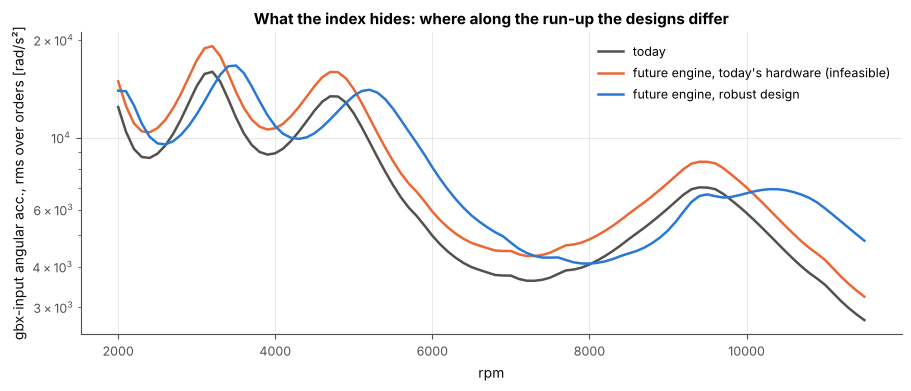

In [7]:
def gbx_acc(d, gas):
    x = x_cal.copy(); x[i_k], x[i_c] = d[0], d[1]; x[i_gas] *= gas
    _, ex = dl.simulate(x, rpm=RPM_F, orders=ORD_F, full_output=True,
                        fixed=dict(dl.FIXED, J_crank=dl.FIXED["J_crank"] + d[2]))
    return np.sqrt((ex["acc_gbx"] ** 2).sum(axis=0) / 2)


fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(RPM_F, gbx_acc(d_today, 1.0), color=plotstyle.MUTED, label="today")
ax.plot(RPM_F, gbx_acc(d_today, GAS_FUTURE), color=C[1], label="future engine, today's hardware (infeasible)")
ax.plot(RPM_F, gbx_acc(d_rob, GAS_FUTURE), color=C[0], label="future engine, robust design")
ax.set(xlabel="rpm", ylabel="gbx-input angular acc., rms over orders [rad/s²]", yscale="log",
       title="What the index hides: where along the run-up the designs differ")
ax.legend()
plt.show()

The index is one number; the curves show *where* the designs are loud. The
stiffer damper of the robust design shifts every resonance crossing up by a few
hundred rpm. Compared with unchanged hardware it lowers the peaks, but it is
louder between them and above 10000 rpm. Whether a resonance at 3500 rpm is
preferable to one at 3000 rpm depends on how the vehicle is used – a weighting
over rpm (a usage profile) would be the next refinement of the objective.

## 7 · Summary

* Formulating objectives and constraints is most of the work. Aggregated
  indices are necessary for optimisers and dangerous for engineers – always
  return to the raw curves.
* Expect optima on constraints; question the constraint values.
* Several objectives → Pareto front (ε-constraint sweep or non-dominated
  filtering; NSGA-II for more objectives). Present the menu, not one point.
* Deterministic optima on active constraints are fragile. Propagate tolerances
  and model uncertainty by Monte Carlo; for robust design, constrain percentiles
  and use common random numbers.
* Robust optimisation multiplies the run count by the sample size – one more
  reason to have a cheap model or a surrogate.

### Try it yourself

1. Raise the damping bound to 1.0 Nms/rad. How does the front move? What would
   that be worth in flywheel inertia?
2. Weight the rattle index by a usage profile (e.g. 70 % of the weight on
   2500–5000 rpm) and recompute the front.
3. Robust Pareto front: repeat the ε-constraint sweep with `robust_eval`.
4. Use the calibration from data set B (`cal["x_B"]`, the biased parameters) as
   the design model and evaluate the resulting "optimum" with the true parameters
   (`cal["x_true"]`). How much of the predicted benefit is real? This is the
   design-side cost of a structurally wrong calibration.

Next: **06 – Bridge to neural networks.**